# CSCI 4360 Final Project

### Name: Bonnie Houston

**Due Date**: go to eLC, click "Tools"->"Assignments" to check for the deadline. Please note that the final project **cannot be submitted late**. The regular late policy does not apply to the final project.

**Submission**: submit this completed Jupyter Notebook file (.ipynb extension) to eLC. Please be sure to **keep all the output cells**, so that the TA can see your outputs directly without running your notebook.

This assignment is to be completed individually. You may use generative AI technology to help you complete this assignment, but you are ultimately responsible for the correctness of your submission.

Tip: if you are running on Colab, be sure to check that you are actually using the GPU. Click the top menu item **"Runtime"->"Change runtime type"**, and make sure **"T4 GPU"** is selected.

### Instructions

This final project focuses on time series forecasting using various models.

#### Dataset
Go to https://archive.ics.uci.edu/dataset/235/individual+household+electric+power+consumption to download and extract the "household_power_consumption.txt" data file.

The dataset does contain some missing values. Please deal with them appropriately.

The forecasting target is "Global_active_power". You can choose to do univariate time series analysis by only focusing on this column. You are also free to use the other columns as additional inputs to your models.

Please chronologically split the data into first 70% for training, next 15% for validation, and the last 15% for testing.

You are to use the most recent 120 minutes of historical data to make forecasts for the next 15 steps. Note that this means you need to make 15 forecast values from t+1 to t+15, not just a single forecast value for t+15.

#### Models

Please test and compare the following models. You must use PyTorch for the neural network models. You are free to tune hyperparameters and design appropriate neural network architectures.

1. A naive forecasting model that simply copies the most recent historical value for forecasting.
2. ARIMA
3. RNN
4. LSTM
5. GRU
6. Conv1d

Please be sure to include a plot that compares the forecasting performance of all the models and a summary of your findings.

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
from google.colab import files
from packaging.version import Version
import sys
import matplotlib.pyplot as plt
IS_COLAB = "google.colab" in sys.modules
if IS_COLAB:
    %pip install -q optuna torchmetrics
import torch
assert Version(torch.__version__) >= Version("2.6.0")
if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"

uploaded = files.upload()

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 419.5/419.5 kB 10.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 37.0 MB/s eta 0:00:00


Saving household_power_consumption.txt to household_power_consumption.txt


In [ ]:

#loading and splitting data
data = pd.read_csv("household_power_consumption.txt", sep=";",  na_values="?")
data["datetime"] = pd.to_datetime(
    data["Date"] + " " + data["Time"],
    dayfirst=True
)
data = data.sort_values("datetime").set_index("datetime")
data.head()
print(data["Global_active_power"].isna().sum()/len(data))
data2 = data[["Global_active_power"]].copy()
data2["Global_active_power"] = data2["Global_active_power"].interpolate()
data2["Global_active_power"] = data2["Global_active_power"].ffill().bfill()
n = len(data2)

train_end = int(0.70 * n)
valid_end = int(0.85 * n)

train = data2.iloc[:train_end]
valid = data2.iloc[train_end:valid_end]
test = data2.iloc[valid_end:]

print(train.shape)
print(valid.shape)
print(test.shape)


0.012518437457686004
(1452681, 1)
(311289, 1)
(311289, 1)


```
PASTED OUTPUT:

0.012518437457686004
(1452681, 1)
(311289, 1)
(311289, 1)

```

In [ ]:
train_values = train["Global_active_power"].values.astype("float32")
valid_values = valid["Global_active_power"].values.astype("float32")
test_values = test["Global_active_power"].values.astype("float32")
def make_windows(train, length = 120, output = 15) :
  x = []
  y = []
  for i in range(len(train)- length - output + 1):
      x_window = train[i:i+length]
      y_window = train[i+length: i+length + output]
      x.append(x_window)
      y.append(y_window)
  return np.array(x), np.array(y)

def regression_metrics(y_true, y_pred):
    true_tensor = torch.tensor(y_true, dtype = torch.float32)
    pred_tensor = torch.tensor(y_pred, dtype = torch.float32)
    mse = torch.mean((true_tensor - pred_tensor) ** 2)
    rmse = torch.sqrt(mse)
    mae = torch.mean(torch.abs(true_tensor - pred_tensor))
    mape_val = torch.mean(torch.abs((true_tensor - pred_tensor) / (true_tensor + 1e-8))) * 100

    return {
        "MSE": mse.item(),
        "RMSE": rmse.item(),
        "MAE": mae.item(),
        "MAPE": mape_val.item()
    }

#windows used for all models
xvalid, yvalid = make_windows(valid_values, 120, 15)
xtest, ytest = make_windows(test_values, 120, 15)


In [ ]:
#naive
xtrain, ytrain = make_windows(train_values, 120, 15)

def naive_model(xtrain, output= 15) :
  lastvals = xtrain[:, -1:]
  preds = np.repeat(lastvals, output, axis=1)
  return preds
preds_naive_train = naive_model(xtrain,15)
naive_metrics_train = regression_metrics(ytrain, preds_naive_train)
results = []
#results.append({"Model":"Naive", **naive_metrics_train})
preds_naive_valid = naive_model(xvalid, 15)
naive_metrics_valid = regression_metrics(yvalid, preds_naive_valid)
preds_naive_test = naive_model(xtest, 15)
naive_metrics_test = regression_metrics(ytest, preds_naive_test)

In [ ]:
#making training model for arima
from statsmodels.tsa.arima.model import ARIMA
model = ARIMA(train_values, order = (2, 1, 2))
arima_fit = model.fit()


In [ ]:
import time
import numpy as np
#predicting at each window using trained model
def arima_apply_windows(arima_fit, X, output=15, max_windows=200, print_every=5000):
    preds = []
    start_time = time.time()

    for i in range(max_windows):
        window_model = arima_fit.apply(X[i])
        forecast = window_model.forecast(steps=output)
        preds.append(np.array(forecast))

        if (i + 1) % print_every == 0 or (i + 1) == max_windows:
            elapsed = time.time() - start_time
            rate = (i + 1) / elapsed
            remaining = max_windows - (i + 1)
            eta_minutes = remaining / rate / 60

            print(
                f"Finished {i+1}/{max_windows} windows | "
                f"{rate:.2f} windows/sec | "
                f"ETA: {eta_minutes:.1f} min"
            )

    return np.array(preds)

compare_n_valid = len(xvalid)
compare_n_test = len(xtest)

arima_valid_preds = arima_apply_windows(
    arima_fit, xvalid, output=15, max_windows=compare_n_valid, print_every=50000
)

arima_test_preds = arima_apply_windows(
    arima_fit, xtest, output=15, max_windows=compare_n_test, print_every=50000
)

arima_valid_metrics = regression_metrics(
    yvalid[:compare_n_valid], arima_valid_preds
)

arima_test_metrics = regression_metrics(
    ytest[:compare_n_test], arima_test_preds
)

arima_valid_metrics, arima_test_metrics

Finished 50000/311155 windows | 158.24 windows/sec | ETA: 27.5 min
Finished 100000/311155 windows | 157.83 windows/sec | ETA: 22.3 min
Finished 150000/311155 windows | 157.60 windows/sec | ETA: 17.0 min
Finished 200000/311155 windows | 157.32 windows/sec | ETA: 11.8 min
Finished 250000/311155 windows | 157.19 windows/sec | ETA: 6.5 min
Finished 300000/311155 windows | 157.29 windows/sec | ETA: 1.2 min
Finished 311155/311155 windows | 157.10 windows/sec | ETA: 0.0 min
Finished 50000/311155 windows | 159.65 windows/sec | ETA: 27.3 min
Finished 100000/311155 windows | 158.42 windows/sec | ETA: 22.2 min
Finished 150000/311155 windows | 158.34 windows/sec | ETA: 17.0 min
Finished 200000/311155 windows | 158.08 windows/sec | ETA: 11.7 min
Finished 250000/311155 windows | 158.10 windows/sec | ETA: 6.4 min
Finished 300000/311155 windows | 157.92 windows/sec | ETA: 1.2 min
Finished 311155/311155 windows | 158.10 windows/sec | ETA: 0.0 min


({'MSE': 0.35917991399765015,
  'RMSE': 0.5993161797523499,
  'MAE': 0.2855948209762573,
  'MAPE': 27.166790008544922},
 {'MSE': 0.2873501479625702,
  'RMSE': 0.5360504984855652,
  'MAE': 0.26444241404533386,
  'MAPE': 35.60877990722656})

```
PASTED OUTPUT:

Finished 50000/311155 windows | 158.24 windows/sec | ETA: 27.5 min
Finished 100000/311155 windows | 157.83 windows/sec | ETA: 22.3 min
Finished 150000/311155 windows | 157.60 windows/sec | ETA: 17.0 min
Finished 200000/311155 windows | 157.32 windows/sec | ETA: 11.8 min
Finished 250000/311155 windows | 157.19 windows/sec | ETA: 6.5 min
Finished 300000/311155 windows | 157.29 windows/sec | ETA: 1.2 min
Finished 311155/311155 windows | 157.10 windows/sec | ETA: 0.0 min
Finished 50000/311155 windows | 159.65 windows/sec | ETA: 27.3 min
Finished 100000/311155 windows | 158.42 windows/sec | ETA: 22.2 min
Finished 150000/311155 windows | 158.34 windows/sec | ETA: 17.0 min
Finished 200000/311155 windows | 158.08 windows/sec | ETA: 11.7 min
Finished 250000/311155 windows | 158.10 windows/sec | ETA: 6.4 min
Finished 300000/311155 windows | 157.92 windows/sec | ETA: 1.2 min
Finished 311155/311155 windows | 158.10 windows/sec | ETA: 0.0 min
({'MSE': 0.35917991399765015,
  'RMSE': 0.5993161797523499,
  'MAE': 0.2855948209762573,
  'MAPE': 27.166790008544922},
 {'MSE': 0.2873501479625702,
  'RMSE': 0.5360504984855652,
  'MAE': 0.26444241404533386,
  'MAPE': 35.60877990722656})
  ```

In [ ]:
import torch.nn as nn
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader


# Convert numpy arrays to tensors
xtrain_tensor = torch.tensor(xtrain, dtype=torch.float32).unsqueeze(-1)
ytrain_tensor = torch.tensor(ytrain, dtype=torch.float32)

xvalid_tensor = torch.tensor(xvalid, dtype=torch.float32).unsqueeze(-1)
yvalid_tensor = torch.tensor(yvalid, dtype=torch.float32)

xtest_tensor = torch.tensor(xtest, dtype=torch.float32).unsqueeze(-1)
ytest_tensor = torch.tensor(ytest, dtype=torch.float32)


# DataLoaders
batch_size = 64

train_dataset = TensorDataset(xtrain_tensor, ytrain_tensor)
valid_dataset = TensorDataset(xvalid_tensor, yvalid_tensor)
test_dataset = TensorDataset(xtest_tensor, ytest_tensor)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
valid_loader = DataLoader(valid_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)


In [ ]:
#training loop for neural network models
def train_model(model, train_loader, valid_loader, num_epochs=10, lr=0.001):
    model = model.to(device)

    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    train_losses = []
    valid_losses = []

    for epoch in range(num_epochs):
        model.train()
        train_loss = 0

        for xb, yb in train_loader:
            xb = xb.to(device)
            yb = yb.to(device)

            preds = model(xb)
            loss = criterion(preds, yb)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            train_loss += loss.item()

        train_loss = train_loss / len(train_loader)

        model.eval()
        valid_loss = 0

        with torch.no_grad():
            for xb, yb in valid_loader:
                xb = xb.to(device)
                yb = yb.to(device)

                preds = model(xb)
                loss = criterion(preds, yb)

                valid_loss += loss.item()

        valid_loss = valid_loss / len(valid_loader)

        train_losses.append(train_loss)
        valid_losses.append(valid_loss)

        print(f"Epoch {epoch+1}/{num_epochs} | Train Loss: {train_loss:.4f} | Valid Loss: {valid_loss:.4f}")

    return model, train_losses, valid_losses

In [ ]:
#neural net models
class RecurrentModel(nn.Module):
    def __init__(self, model_type="RNN", hidden_size=128, num_layers=2, output_size=15):
        super().__init__()

        if model_type == "RNN":
            self.recurrent = nn.RNN(1, hidden_size, num_layers=num_layers, batch_first=True)
        elif model_type == "LSTM":
            self.recurrent = nn.LSTM(1, hidden_size, num_layers=num_layers, batch_first=True)
        elif model_type == "GRU":
            self.recurrent = nn.GRU(1, hidden_size, num_layers=num_layers, batch_first=True)
        else:
            raise ValueError("model_type must be 'RNN', 'LSTM', or 'GRU'")
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        out, _ = self.recurrent(x)
        last_output = out[:, -1, :]
        return self.fc(last_output)

rnn_model = RecurrentModel("RNN").to(device)
lstm_model = RecurrentModel("LSTM").to(device)
gru_model = RecurrentModel("GRU").to(device)

class Conv1DModel(nn.Module):
    def __init__(self, output_size=15):
        super().__init__()

        self.conv1 = nn.Conv1d(1, 64, kernel_size=5, padding=2)
        self.relu = nn.ReLU()
        self.conv2 = nn.Conv1d(64, 128, kernel_size=5, padding=2)
        self.conv3 = nn.Conv1d(128, 128, kernel_size=3, padding=1)

        self.fc = nn.Linear(128 * 120, output_size)

    def forward(self, x):
        x = x.permute(0, 2, 1)

        x = self.relu(self.conv1(x))
        x = self.relu(self.conv2(x))
        x = self.relu(self.conv3(x))

        x = x.flatten(start_dim=1)
        return self.fc(x)
conv_model = Conv1DModel(output_size=15).to(device)


In [ ]:
rnn_model = RecurrentModel("RNN")
rnn_model, rnn_train_losses, rnn_valid_losses = train_model(
    rnn_model, train_loader, valid_loader
)


Epoch 1/10 | Train Loss: 0.3669 | Valid Loss: 0.3212
Epoch 2/10 | Train Loss: 0.3602 | Valid Loss: 0.3190
Epoch 3/10 | Train Loss: 0.3587 | Valid Loss: 0.3203
Epoch 4/10 | Train Loss: 0.3575 | Valid Loss: 0.3226
Epoch 5/10 | Train Loss: 0.3581 | Valid Loss: 0.3312
Epoch 6/10 | Train Loss: 0.3596 | Valid Loss: 0.3254
Epoch 7/10 | Train Loss: 0.3584 | Valid Loss: 0.3237
Epoch 8/10 | Train Loss: 0.3585 | Valid Loss: 0.3240
Epoch 9/10 | Train Loss: 0.3586 | Valid Loss: 0.3235
Epoch 10/10 | Train Loss: 0.3581 | Valid Loss: 0.3194


```
PASTED OUTPUT:

Epoch 1/10 | Train Loss: 0.3669 | Valid Loss: 0.3212
Epoch 2/10 | Train Loss: 0.3602 | Valid Loss: 0.3190
Epoch 3/10 | Train Loss: 0.3587 | Valid Loss: 0.3203
Epoch 4/10 | Train Loss: 0.3575 | Valid Loss: 0.3226
Epoch 5/10 | Train Loss: 0.3581 | Valid Loss: 0.3312
Epoch 6/10 | Train Loss: 0.3596 | Valid Loss: 0.3254
Epoch 7/10 | Train Loss: 0.3584 | Valid Loss: 0.3237
Epoch 8/10 | Train Loss: 0.3585 | Valid Loss: 0.3240
Epoch 9/10 | Train Loss: 0.3586 | Valid Loss: 0.3235
Epoch 10/10 | Train Loss: 0.3581 | Valid Loss: 0.3194
```

In [ ]:
lstm_model = RecurrentModel("LSTM")
lstm_model, lstm_train_losses, lstm_valid_losses = train_model(
    lstm_model, train_loader, valid_loader
)


Epoch 1/10 | Train Loss: 0.3214 | Valid Loss: 0.2833
Epoch 2/10 | Train Loss: 0.2950 | Valid Loss: 0.2749
Epoch 3/10 | Train Loss: 0.2815 | Valid Loss: 0.2761
Epoch 4/10 | Train Loss: 0.2695 | Valid Loss: 0.2752
Epoch 5/10 | Train Loss: 0.2572 | Valid Loss: 0.2876
Epoch 6/10 | Train Loss: 0.2453 | Valid Loss: 0.2974
Epoch 7/10 | Train Loss: 0.2344 | Valid Loss: 0.3052
Epoch 8/10 | Train Loss: 0.2246 | Valid Loss: 0.3165
Epoch 9/10 | Train Loss: 0.2156 | Valid Loss: 0.3270
Epoch 10/10 | Train Loss: 0.2079 | Valid Loss: 0.3420


```
PASTED OUTPUT:

Epoch 1/10 | Train Loss: 0.3214 | Valid Loss: 0.2833
Epoch 2/10 | Train Loss: 0.2950 | Valid Loss: 0.2749
Epoch 3/10 | Train Loss: 0.2815 | Valid Loss: 0.2761
Epoch 4/10 | Train Loss: 0.2695 | Valid Loss: 0.2752
Epoch 5/10 | Train Loss: 0.2572 | Valid Loss: 0.2876
Epoch 6/10 | Train Loss: 0.2453 | Valid Loss: 0.2974
Epoch 7/10 | Train Loss: 0.2344 | Valid Loss: 0.3052
Epoch 8/10 | Train Loss: 0.2246 | Valid Loss: 0.3165
Epoch 9/10 | Train Loss: 0.2156 | Valid Loss: 0.3270
Epoch 10/10 | Train Loss: 0.2079 | Valid Loss: 0.3420
```

In [ ]:
gru_model = RecurrentModel("GRU")
gru_model, gru_train_losses, gru_valid_losses = train_model(
    gru_model, train_loader, valid_loader
)


Epoch 1/10 | Train Loss: 0.3194 | Valid Loss: 0.2850
Epoch 2/10 | Train Loss: 0.2909 | Valid Loss: 0.2795
Epoch 3/10 | Train Loss: 0.2690 | Valid Loss: 0.2951
Epoch 4/10 | Train Loss: 0.2516 | Valid Loss: 0.3034
Epoch 5/10 | Train Loss: 0.2392 | Valid Loss: 0.3172
Epoch 6/10 | Train Loss: 0.2296 | Valid Loss: 0.3144
Epoch 7/10 | Train Loss: 0.2215 | Valid Loss: 0.3269
Epoch 8/10 | Train Loss: 0.2149 | Valid Loss: 0.3339
Epoch 9/10 | Train Loss: 0.2092 | Valid Loss: 0.3310
Epoch 10/10 | Train Loss: 0.2045 | Valid Loss: 0.3319


```
PASTED OUTPUT:

Epoch 1/10 | Train Loss: 0.3194 | Valid Loss: 0.2850
Epoch 2/10 | Train Loss: 0.2909 | Valid Loss: 0.2795
Epoch 3/10 | Train Loss: 0.2690 | Valid Loss: 0.2951
Epoch 4/10 | Train Loss: 0.2516 | Valid Loss: 0.3034
Epoch 5/10 | Train Loss: 0.2392 | Valid Loss: 0.3172
Epoch 6/10 | Train Loss: 0.2296 | Valid Loss: 0.3144
Epoch 7/10 | Train Loss: 0.2215 | Valid Loss: 0.3269
Epoch 8/10 | Train Loss: 0.2149 | Valid Loss: 0.3339
Epoch 9/10 | Train Loss: 0.2092 | Valid Loss: 0.3310
Epoch 10/10 | Train Loss: 0.2045 | Valid Loss: 0.3319
```

In [ ]:
conv_model = Conv1DModel()
conv_model, conv_train_losses, conv_valid_losses = train_model(
    conv_model, train_loader, valid_loader
)

Epoch 1/10 | Train Loss: 0.3205 | Valid Loss: 0.2842
Epoch 2/10 | Train Loss: 0.3062 | Valid Loss: 0.2881
Epoch 3/10 | Train Loss: 0.3014 | Valid Loss: 0.2826
Epoch 4/10 | Train Loss: 0.2973 | Valid Loss: 0.2849
Epoch 5/10 | Train Loss: 0.2937 | Valid Loss: 0.2872
Epoch 6/10 | Train Loss: 0.2907 | Valid Loss: 0.2867
Epoch 7/10 | Train Loss: 0.2877 | Valid Loss: 0.2867
Epoch 8/10 | Train Loss: 0.2851 | Valid Loss: 0.2898
Epoch 9/10 | Train Loss: 0.2827 | Valid Loss: 0.2909
Epoch 10/10 | Train Loss: 0.2804 | Valid Loss: 0.2919


```
PASTED OUTPUT:

Epoch 1/10 | Train Loss: 0.3205 | Valid Loss: 0.2842
Epoch 2/10 | Train Loss: 0.3062 | Valid Loss: 0.2881
Epoch 3/10 | Train Loss: 0.3014 | Valid Loss: 0.2826
Epoch 4/10 | Train Loss: 0.2973 | Valid Loss: 0.2849
Epoch 5/10 | Train Loss: 0.2937 | Valid Loss: 0.2872
Epoch 6/10 | Train Loss: 0.2907 | Valid Loss: 0.2867
Epoch 7/10 | Train Loss: 0.2877 | Valid Loss: 0.2867
Epoch 8/10 | Train Loss: 0.2851 | Valid Loss: 0.2898
Epoch 9/10 | Train Loss: 0.2827 | Valid Loss: 0.2909
Epoch 10/10 | Train Loss: 0.2804 | Valid Loss: 0.2919



```

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
#collecting predictions
def get_model_predictions(model, data_loader):
    model.eval()
    preds_list = []

    with torch.no_grad():
        for xb, yb in data_loader:
            xb = xb.to(device)

            preds = model(xb)
            preds_list.append(preds.cpu())

    return torch.cat(preds_list, dim=0).numpy()
# Choose same number of test windows for every model
#(although with this they should all be the same length regardless)
compare_n = len(arima_test_preds)

# neural net predictions
rnn_test_preds = get_model_predictions(rnn_model, test_loader)[:compare_n]
lstm_test_preds = get_model_predictions(lstm_model, test_loader)[:compare_n]
gru_test_preds = get_model_predictions(gru_model, test_loader)[:compare_n]
conv_test_preds = get_model_predictions(conv_model, test_loader)[:compare_n]

# Naive predictions
naive_test_preds = naive_model(xtest[:compare_n], output=15)

# Store all predictions
test_preds = {
    "Naive": naive_test_preds,
    "ARIMA": arima_test_preds[:compare_n],
    "RNN": rnn_test_preds,
    "LSTM": lstm_test_preds,
    "GRU": gru_test_preds,
    "Conv1d": conv_test_preds
}

# Metrics table
results = []

for name, preds in test_preds.items():
    metrics = regression_metrics(ytest[:compare_n], preds)
    results.append({"Model": name, **metrics})

results_df = pd.DataFrame(results)
results_df



,Model,MSE,RMSE,MAE,MAPE
0,Naive,0.293947,0.542169,0.261220,34.922176
1,ARIMA,0.287350,0.536050,0.264442,35.608780
2,RNN,0.253470,0.503458,0.277992,42.332329
3,LSTM,0.252221,0.502216,0.267283,37.399807
4,GRU,0.244787,0.494760,0.256056,32.922955
5,Conv1d,0.226991,0.476435,0.260942,36.572254


```
PASTED OUTPUT:

index,Model,MSE,RMSE,MAE,MAPE
0,Naive,0.2939472198486328,0.5421689748764038,0.2612203061580658,34.922176361083984
1,ARIMA,0.2873501479625702,0.5360504984855652,0.26444241404533386,35.60877990722656
2,RNN,0.2534703314304352,0.5034583806991577,0.27799153327941895,42.33232879638672
3,LSTM,0.2522212862968445,0.5022163987159729,0.267283171415329,37.39980697631836
4,GRU,0.24478738009929657,0.4947599172592163,0.2560555934906006,32.92295455932617
5,Conv1d,0.22699056565761566,0.47643527388572693,0.26094239950180054,36.5722541809082    
```

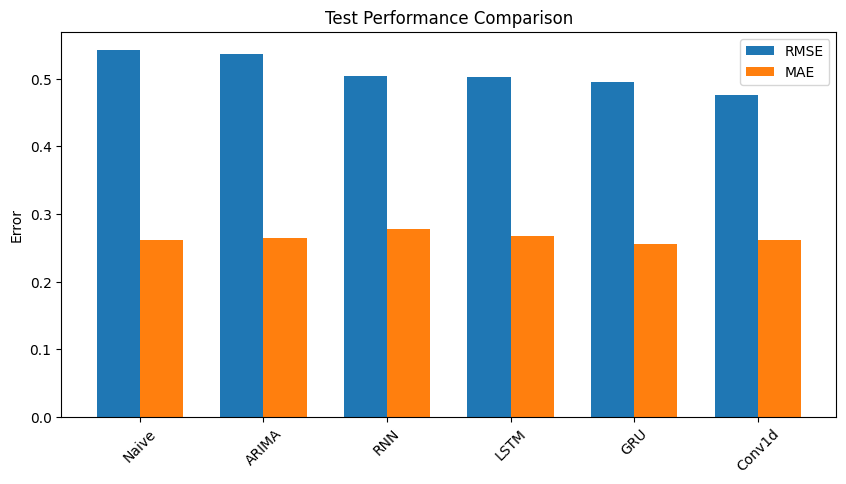

In [ ]:
#plotting performance comparison
plt.figure(figsize=(10, 5))

x = np.arange(len(results_df["Model"]))
width = 0.35

plt.bar(x - width/2, results_df["RMSE"], width, label="RMSE")
plt.bar(x + width/2, results_df["MAE"], width, label="MAE")

plt.xticks(x, results_df["Model"], rotation=45)
plt.ylabel("Error")
plt.title("Test Performance Comparison")
plt.legend()
plt.show()

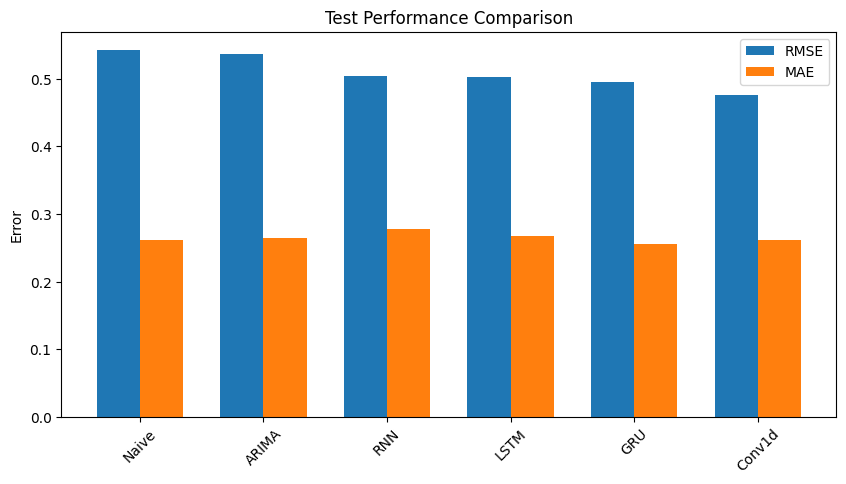

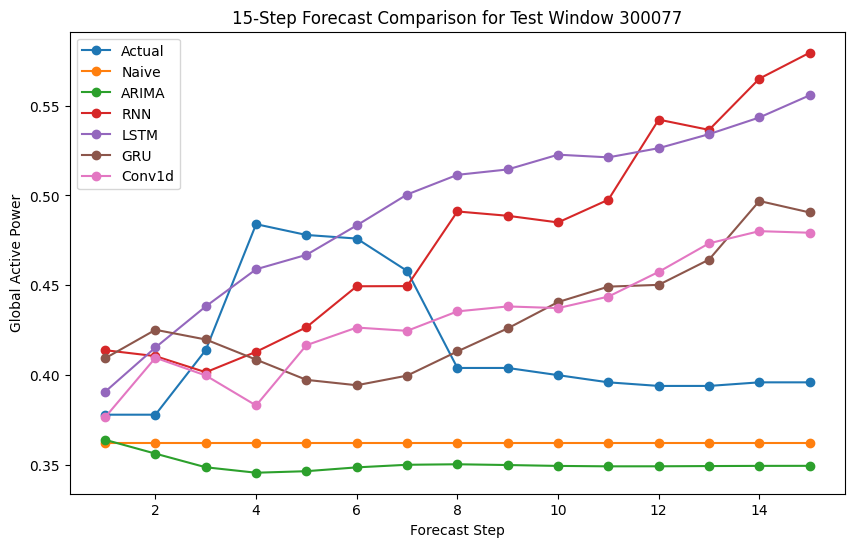

In [ ]:
#comparing predictions
sample_idx = 300077
steps = np.arange(1, 16)

plt.figure(figsize=(10, 6))

plt.plot(steps, ytest[sample_idx], marker="o", label="Actual")

for name, preds in test_preds.items():
    plt.plot(steps, preds[sample_idx], marker="o", label=name)

plt.xlabel("Forecast Step")
plt.ylabel("Global Active Power")
plt.title(f"15-Step Forecast Comparison for Test Window {sample_idx}")
plt.legend()
plt.show()

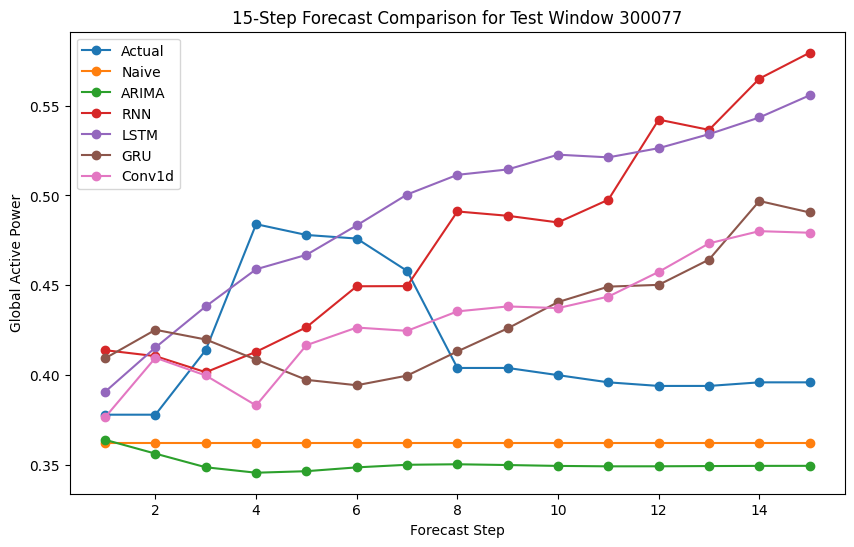

Summary:
The results suggest that GRU and Conv1d models are both strong. Conv1d had the lowest RMSE and MSE, which penalize larger errors, while GRU had the lowest MAE and MAPE. This means the GRU model may have made larger errors on some individual predictions, but it was more accurate on average across all forecast points. The naive model had worse performance overall but was not far behind. This suggests that household power consumption is fairly consistent over short intervals. Overall, these error values are reasonable given the data, suggesting the models are useful for short-term forecasting.